# Inversion and identification limits

Use the finite-ER moment curve to recover selected parameters, then enumerate an exact example of structural ambiguity.

中文：用有限ER矩曲线进行条件反演，再用精确枚举展示内部网络的识别边界。

In [1]:
from pathlib import Path
import sys, os, csv
ROOT = Path.cwd()
while not (ROOT / "src/econophysics").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
def read_table(name):
    with (ROOT / "results/tables" / name).open() as f:
        return list(csv.DictReader(f))
print("Repository found. Shared implementation and frozen tables are available.")

Repository found. Shared implementation and frozen tables are available.


## 1. Invert the population relations

With known $N,u$, fixed $0<q<1$ and $\lambda>0$,

$$q=\frac{\mathbb E[V]}{uN},\qquad A_N(c)=\mathbb E[S_2]=\frac{\operatorname{Var}(V)}{q(1-q)u^2}.$$

The mean-degree parameter is called `rho` in the shared implementation. The finite curve is strictly increasing: an edge joining groups of sizes $a,b$ increases $S_2$ by $2ab$.

In [2]:
from econophysics.physics_inference import finite_er_moments, volume_moment_estimate
curve = [{k: float(v) for k, v in row.items()} for row in read_table("depth_study_v1/finite_er_curve.csv")]
assert len(curve) == 107
assert np.all(np.diff([r["s2"] for r in curve]) > 0)
N, q, u, lam, true_c = 128, 0.2, 1.0, 0.02, 1.0
point = next(row for row in curve if np.isclose(row["rho"], true_c))
features = {"volume_mean": q*u*N, "volume_std": np.sqrt(q*(1-q)*u*u*point["s2"])}
estimate = volume_moment_estimate(features, curve, n=N, unit_order=u)
print("Population estimate:", estimate)
assert np.isclose(estimate["rho"], true_c)
assert np.isclose(estimate["q"], q)
var_r = q*(lam/N)**2*point["s2"]
lam_squared = N*N*u*u*(1-q)*var_r/features["volume_std"]**2
assert np.isclose(np.sqrt(lam_squared), lam)
print("Recovered price response:", np.sqrt(lam_squared))

Population estimate: {'rho': 1.0, 'q': 0.2, 's2': np.float64(1067.5931655283903), 'flag': 'interior'}
Recovered price response: 0.02


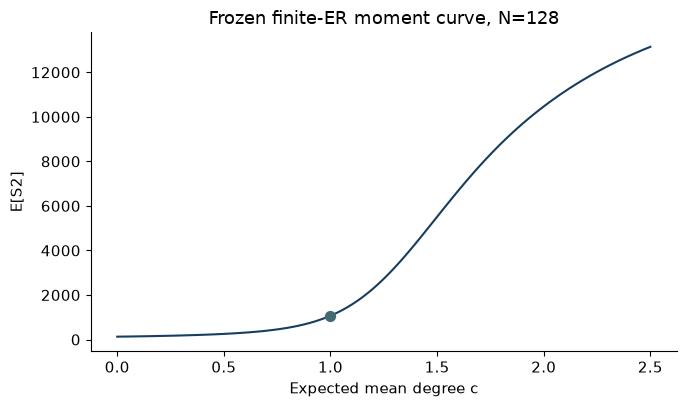

In [3]:
rr = [r for r in curve if r["rho"] <= 2.5]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([r["rho"] for r in rr], [r["s2"] for r in rr], color="#173e60")
ax.scatter([true_c], [point["s2"]], color="#416b73", s=50, zorder=3)
ax.set(xlabel="Expected mean degree c", ylabel="E[S2]", title="Frozen finite-ER moment curve, N=128")
fig.tight_layout(); plt.show()

## 2. Check the finite recurrence directly

The shared routine computes the root-component distribution using high-precision arithmetic. This is a finite probability calculation rather than an infinite-system approximation.

In [4]:
check_points = [finite_er_moments(8, c) for c in [0, 0.5, 1, 2, 7]]
assert check_points[0]["s2"] == 8
assert check_points[-1]["s2"] == 64
assert all(np.isclose(r["probability_mass"], 1) for r in check_points)
assert np.all(np.diff([r["s2"] for r in check_points]) > 0)
for c, r in zip([0, 0.5, 1, 2, 7], check_points): print(c, r)

0 {'s2': 8.0, 's3': 8.0, 'probability_mass': 1.0}
0.5 {'s2': 14.165218497594362, 's3': 36.58350187810587, 'probability_mass': 1.0}
1 {'s2': 25.279214090748777, 's3': 117.39103367630216, 'probability_mass': 1.0}
2 {'s2': 50.20119818301802, 's3': 356.7525515286011, 'probability_mass': 1.0}
7 {'s2': 64.0, 's3': 512.0, 'probability_mass': 1.0}


## 3. Enumerate the chain and star

Both graphs form one connected group of four. The observation rule depends on group sizes, so every possible $(r,V)$ outcome has the same probability in the two graphs.

In [5]:
from econophysics.model import components
from fractions import Fraction as F
from itertools import product
chain = [(0,1), (1,2), (2,3)]
star = [(0,1), (0,2), (0,3)]
def exact_observation_law(edges):
    sizes = [len(g) for g in components(4, edges)]
    law = {}
    for actions in product([-1,0,1], repeat=len(sizes)):
        probability = F(1)
        for action in actions: probability *= F(1,10) if action else F(4,5)
        r = F(1,50)/4 * sum(s*a for s,a in zip(sizes, actions))
        volume = sum(s*abs(a) for s,a in zip(sizes, actions))
        law[r,volume] = law.get((r,volume), F(0)) + probability
    return law
chain_law, star_law = exact_observation_law(chain), exact_observation_law(star)
assert chain != star
assert chain_law == star_law
assert sum(chain_law.values()) == 1
for (r,v), probability in sorted(chain_law.items()):
    print(f"r={str(r):>5}, V={v}, probability={probability}")

r=-1/50, V=4, probability=1/10
r=    0, V=0, probability=4/5
r= 1/50, V=4, probability=1/10


## 4. Compare finite-window benchmark errors

The exact identities concern population information. D01 measures finite-window errors over ten independent studies. Read the frozen table rather than treating the population demonstration as a benchmark.

In [6]:
metrics = read_table("depth_study_v1/summary_metrics.csv")
for row in metrics:
    if row["test_split"] == "unseen" and float(row["lambda_multiplier"]) == 1:
        print(row["method"], "MAE", row["mean_mae"], "independent studies", row["replications"])
print("Exact population identification and finite-sample recovery answer different questions.")

RBF_return MAE 0.045076630446871144 independent studies 10
RBF_joint MAE 0.02688216038647422 independent studies 10
RBF_volume MAE 0.03684860962155166 independent studies 10
RBF_shape_joint MAE 0.031012510449872233 independent studies 10
Moment_volume MAE 0.027113662259715714 independent studies 10
Exact population identification and finite-sample recovery answer different questions.


**Continue:** [Market tests and historical forecasting](03_market_and_forecasting.ipynb). The complete joint characteristic-function argument and the broader mixture certificate are in `docs/theory/FOUNDATIONS.md`.